# 01. Инвентаризация данных

**Цель:** проверить структуру датасета, распределение по группам, качество EDF-файлов и длительности записей.

In [7]:
# Необходимые импорты и порты
import os
from pathlib import Path
os.chdir(r"C:\Users\Home\Desktop\PTSD EEG")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Метаданные испытуемых

Загружаем таблицу метаданных, проверяем распределение по группам и возрастной состав контрольной группы.

In [8]:
#  Метаданные
meta = pd.read_csv("data/metadata.csv")
print("Форма:", meta.shape)
print("\nГруппы:")
print(meta.groupby("group").size())
print("\nВключено:", meta["include"].sum())
print("Исключено:", (~meta["include"]).sum())
print("\nВозраст (Норма):")
print(meta[meta["group"] == "Норма"]["age"].describe().round(1))
print("\nПример:")
print(meta[["subject_id", "group", "age", "n_files", "has_rest"]].head(10))

Форма: (166, 10)

Группы:
group
Норма            67
ПТСР             25
Соматоформные    74
dtype: int64

Включено: 164
Исключено: 2

Возраст (Норма):
count    67.0
mean     33.9
std      11.9
min      19.0
25%      23.0
50%      32.0
75%      44.0
max      58.0
Name: age, dtype: float64

Пример:
  subject_id  group   age  n_files  has_rest
0   КС010_19  Норма  19.0        6      True
1   КС011_25  Норма  25.0        6      True
2   КС012_58  Норма  58.0        6      True
3   КС013_23  Норма  23.0        6      True
4   КС014_22  Норма  22.0        6      True
5   КС015_35  Норма  35.0        6      True
6   КС016_22  Норма  22.0        6      True
7   КС017_51  Норма  51.0        6      True
8   КС022_22  Норма  22.0        6      True
9   КС023_20  Норма  20.0        6      True


## Контроль качества EDF-файлов

Проверяем статус каждого EDF после предобработки. Ожидается, что все 984 файла (164 × 6) успешно обработаны. Пропущенные файлы — единичные случаи (слишком короткие записи Шульте).

In [9]:
qc = pd.read_csv("data/edf_qc_full.csv")
print("Всего файлов:", len(qc))
print("\nСтатусы:")
print(qc["status"].value_counts())
print("\nПропущенные файлы:")
print(qc[qc["status"] == "skipped"][["subject_id", "group", "file", "reason"]])

Всего файлов: 984

Статусы:
status
ok    984
Name: count, dtype: int64

Пропущенные файлы:
Empty DataFrame
Columns: [subject_id, group, file, reason]
Index: []


C:\Users\Home\AppData\Local\Temp\ipykernel_12928\1630415658.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ok, x="group", y="bad_fraction", ax=ax, palette="Set2")


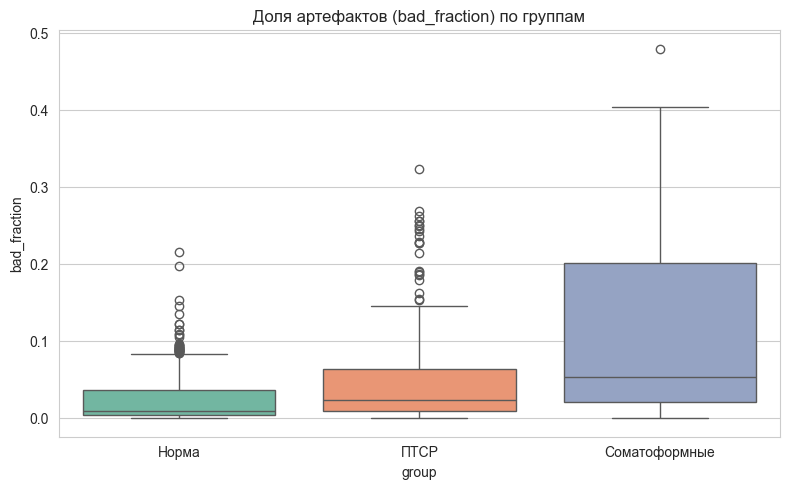


Средний bad_fraction по группам:
               count    mean     std     min     25%     50%     75%     max
group                                                                       
Норма          402.0  0.0265  0.0342  0.0003  0.0041  0.0090  0.0362  0.2158
ПТСР           150.0  0.0579  0.0766  0.0000  0.0090  0.0234  0.0646  0.3237
Соматоформные  432.0  0.1086  0.1104  0.0001  0.0206  0.0535  0.2014  0.4800


In [10]:
ok = qc[qc["status"] == "ok"].copy()

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=ok, x="group", y="bad_fraction", ax=ax, palette="Set2")
ax.set_title("Доля артефактов (bad_fraction) по группам")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_bad_fraction.png", dpi=120)
plt.show()

print("\nСредний bad_fraction по группам:")
print(ok.groupby("group")["bad_fraction"].describe().round(4))

## Длительности записей

Покой обрезан до 60 с для сопоставимости между испытуемыми. Длительность Шульте — индивидуальна и отражает темп выполнения задачи. Проверяем, что все записи имеют приемлемую длительность для спектрального анализа.

C:\Users\Home\AppData\Local\Temp\ipykernel_12928\2675485545.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=subset, x="group", y="duration", ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_12928\2675485545.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=subset, x="group", y="duration", ax=ax, palette="Set2")


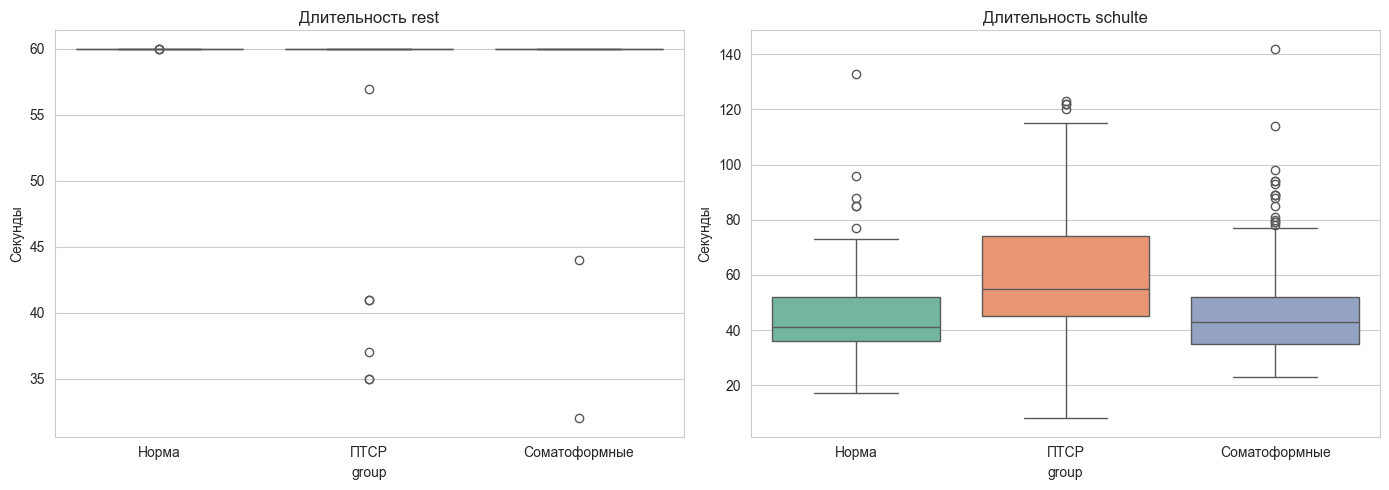

Длительность покоя:
count    164.00
mean      59.04
std        4.57
min       32.00
25%       60.01
50%       60.01
75%       60.01
max       60.01
Name: duration, dtype: float64

Длительность Шульте:
count    820.00
mean      47.59
std       16.86
min        8.00
25%       36.00
50%       44.00
75%       53.00
max      142.00
Name: duration, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ttype in zip(axes, ["rest", "schulte"]):
    subset = ok[ok["trial_type"] == ttype]
    sns.boxplot(data=subset, x="group", y="duration", ax=ax, palette="Set2")
    ax.set_title(f"Длительность {ttype}")
    ax.set_ylabel("Секунды")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_durations.png", dpi=120)
plt.show()

print("Длительность покоя:")
print(ok[ok["trial_type"] == "rest"]["duration"].describe().round(2))
print("\nДлительность Шульте:")
print(ok[ok["trial_type"] == "schulte"]["duration"].describe().round(2))

## Выводы

### Структура выборки

- **Всего:** 166 испытуемых (67 Норма, 25 ПТСР, 74 Соматоформные).
- **Исключены из анализа:** 2 испытуемых.
  - **XCFU5** (Соматоформные) — 5 EDF-файлов Шульте с размером 0 байт (не сохранились при выгрузке из прибора).
  - **ASDF9** (Соматоформные) — запись Шульте T-4 длительностью 1 с, непригодна для спектрального анализа.
- **Итоговая выборка:** 164 испытуемых (67 Норма, 25 ПТСР, 72 Соматоформные).

### Возраст контрольной группы

- 67 испытуемых, 19–58 лет, медиана 32, среднее 33.9 ± 11.9.
- Возраст **Нормы смещён к младшим** возрастам (75-й перцентиль — 44 года).
- Возраст ПТСР и Соматоформных **не закодирован** в данных — это ограничение анализа конфаундеров.

### Качество сигнала

- Все **984 EDF-файла** успешно обработаны после ресемплинга к 125 Гц.
- **Средний `bad_fraction`** (доля сэмплов с отклонением > 5×MAD):
  - Норма: **0.027** (медиана 0.009)
  - ПТСР: **0.058** (медиана 0.023)
  - Соматоформные: **0.109** (медиана 0.054)
- **Артефактов больше у ПТСР (×2) и Соматоформных (×4)** по сравнению с Нормой. Это отражает разные условия съёмки (клиническая когорта vs гражданские добровольцы), а также возможно — физиологические особенности групп.

### Длительности записей

- **Покой:** обрезан до 60 с для сопоставимости. Медиана 60.01 с, у одного испытуемого (PLQW8, Соматоформные) — 32 с.
- **Шульте:** 820 файлов (164 × 5). Медиана 44 с, разброс 8–142 с (индивидуальный темп выполнения).
- Длительность Шульте **варьируется сильнее у ПТСР** (стд ~17 с против ~13 с у Нормы и Соматоформных).

### Следствия для анализа

1. **Ресемплинг обязателен** — fs в исходных EDF варьировалась от 123 до 127 Гц.
2. **Разная длительность Шульте** компенсируется относительными признаками и агрегацией по пробам.
3. **Больший `bad_fraction` у ПТСР и Соматоформных** требует контроля при интерпретации признаков, чувствительных к качеству сигнала (например, coherence).

## Группа 65+ в облаке организатора

В облаке организатора дополнительно присутствует группа
«нормальное старение» (23 испытуемых, 65–70 лет). Мы **не включаем
её в обучение** по следующим причинам:

1. **Гипотеза исследования.** Исходная задача — разделение ПТСР
   (клиническая когорта 18–45 лет) и молодого контроля (гражданские
   добровольцы 19–58 лет). Добавление 65+ меняет гипотезу на
   «ПТСР vs {молодой, пожилой контроль}», что усложняет задачу
   и снижает чувствительность на ПТСР.

2. **Возрастной конфаундер.** Внутри исходного контроля уже
   обнаружена умеренная связь предсказаний с возрастом
   (Spearman ρ = −0.295, p = 0.015). Добавление 65+ усилит
   возрастной разрыв между ПТСР и контролем, что увеличит
   конфаундер.

3. **Дисбаланс классов.** Соотношение ПТСР : Норма вырастет
   с 1 : 2.7 до 1 : 5.2, что негативно влияет на ROC-AUC
   и специфичность.

4. **Возраст ПТСР неизвестен.** В группе ПТСР возраст не закодирован.
   Мы не можем гарантировать, что в клинической когорте присутствуют
   пожилые. Модель может выучить «65+ = контроль», что не имеет
   физиологического смысла.

Финальная модель обучена на исходных 164 испытуемых
(67 контроль, 25 ПТСР, 72 соматоформные). Группа 65+ сохранена
для внешней проверки специфичности и не влияет на обучение
и метрики модели.